# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/ANALYTICS/Colaboratory/data/credit_risk_dataset.csv')

In [4]:
print("Розмір датасету")
print(f"Рядків: {df.shape[0]}, Стовпців: {df.shape[1]}")

print("Перші 5 рядків датасету")
print(df.head())

print("Загальна інформація про дані")
print(df.info())

print("Розподіл цільової змінної (loan_status)")
class_distribution = df['loan_status'].value_counts(normalize=True) * 100
print(class_distribution.map("{:.2f}%".format))

Розмір датасету
Рядків: 32581, Стовпців: 12
Перші 5 рядків датасету
   person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT              123.0   
1          21           9600                   OWN                5.0   
2          25           9600              MORTGAGE                1.0   
3          23          65500                  RENT                4.0   
4          24          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0    PERSONAL          D      35000          16.02            1   
1   EDUCATION          B       1000          11.14            0   
2     MEDICAL          C       5500          12.87            1   
3     MEDICAL          C      35000          15.23            1   
4     MEDICAL          C      35000          14.27            1   

   loan_percent_income cb_person_default_on_file  cb_person_cred_hist_length  
0          


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


Аналіз та заповнення пропущених значень
Відсоток пропусків у колонках:
Пропусків немає

Перевірка після заповнення (сума пропусків): 0
Базова статистика числових змінних
         person_age  person_income  person_emp_length     loan_amnt  \
count  32581.000000   3.258100e+04       32581.000000  32581.000000   
mean      27.734600   6.607485e+04           4.767994   9589.371106   
std        6.348078   6.198312e+04           4.087372   6322.086646   
min       20.000000   4.000000e+03           0.000000    500.000000   
25%       23.000000   3.850000e+04           2.000000   5000.000000   
50%       26.000000   5.500000e+04           4.000000   8000.000000   
75%       30.000000   7.920000e+04           7.000000  12200.000000   
max      144.000000   6.000000e+06         123.000000  35000.000000   

       loan_int_rate   loan_status  loan_percent_income  \
count   32581.000000  32581.000000         32581.000000   
mean       11.009620      0.218164             0.170203   
std         3

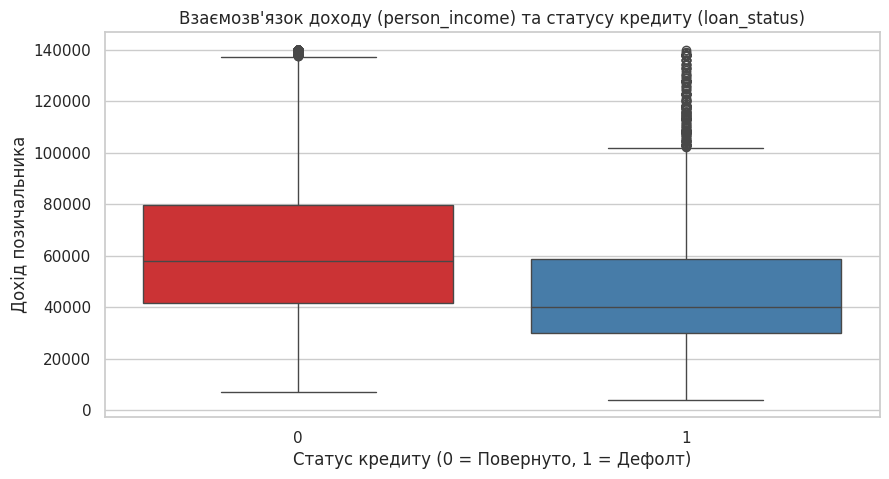

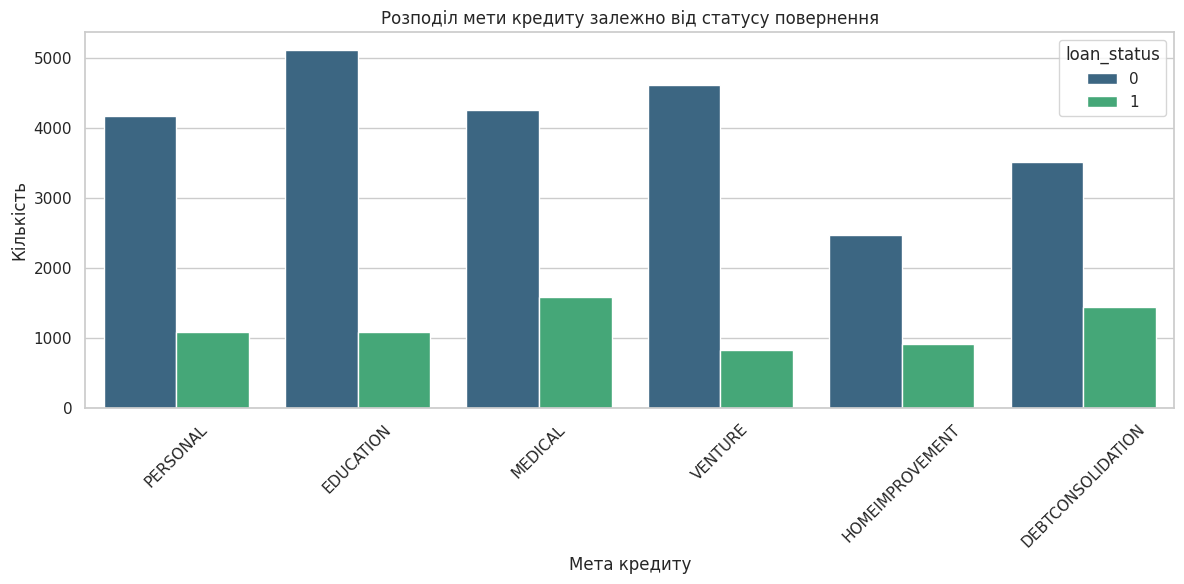

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Аналіз та заповнення пропущених значень")
missing_percent = (df.isnull().sum() / len(df)) * 100
print("Відсоток пропусків у колонках:")
print(missing_percent[missing_percent > 0] if missing_percent.sum() > 0 else "Пропусків немає")

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['int64', 'float64']:
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("\nПеревірка після заповнення (сума пропусків):", df.isnull().sum().sum())

print("Базова статистика числових змінних")
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
print(df[numeric_cols].describe())

print("Обробка викидів у person_incom")
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = len(df[(df['person_income'] < lower_bound) | (df['person_income'] > upper_bound)])
print(f"Знайдено викидів в person_income: {outliers_count} з {len(df)} рядків")

df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()
print(f"Розмір датасету після видалення викидів: {df_clean.shape}")

print("Частота категоріальних змінних відносно цільової")
categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    print(f"\nЧастота значень для колонки '{col}':")
    print(df_clean[col].value_counts())

    print(f"\nЧастка дефолтів (loan_status) для кожного значення '{col}':")
    print(df_clean.groupby(col)['loan_status'].mean())

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='loan_status', y='person_income', hue='loan_status', palette='Set1', legend=False)
plt.title('Взаємозв\'язок доходу (person_income) та статусу кредиту (loan_status)')
plt.xlabel('Статус кредиту (0 = Повернуто, 1 = Дефолт)')
plt.ylabel('Дохід позичальника')
plt.show()

if 'loan_intent' in df_clean.columns:
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df_clean, x='loan_intent', hue='loan_status', palette='viridis')
    plt.title('Розподіл мети кредиту залежно від статусу повернення')
    plt.xticks(rotation=45)
    plt.xlabel('Мета кредиту')
    plt.ylabel('Кількість')
    plt.tight_layout()
    plt.show()



---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



Обчислення матриці кореляцій


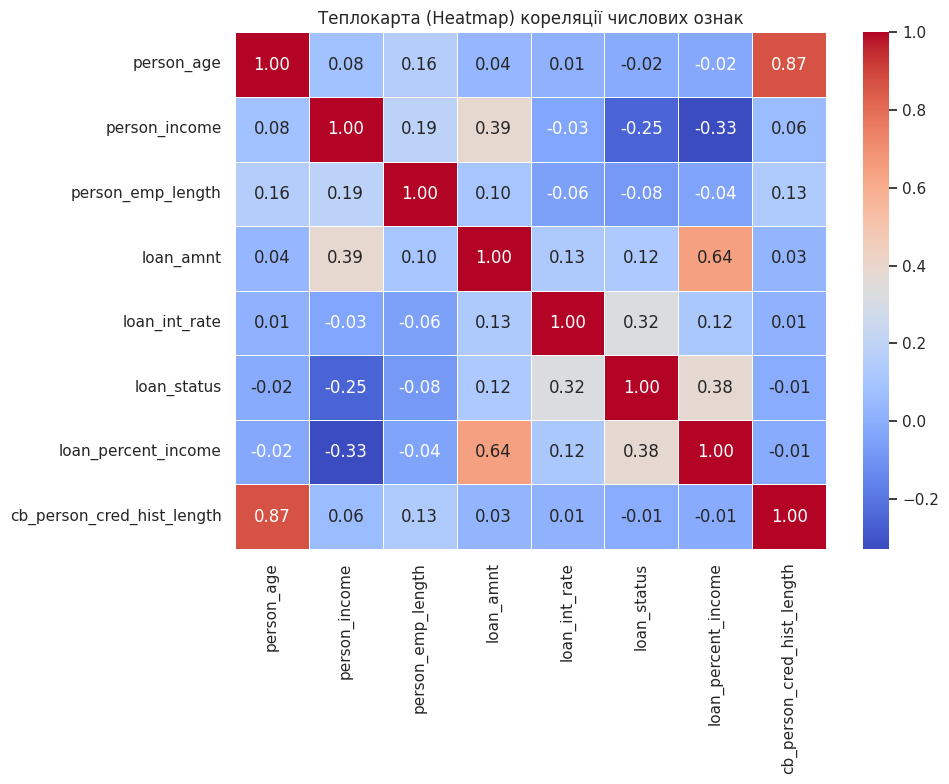

Фінальний набір ознак сформовано
Загальна кількість ознак (X): 22
Кількість записів: 31097

Список фінальних колонок:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'loan_grade_B', 'loan_grade_C', 'loan_grade_D', 'loan_grade_E', 'loan_grade_F', 'loan_grade_G', 'cb_person_default_on_file_Y']


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_fe = df_clean.copy()

print("Обчислення матриці кореляцій")
numeric_cols = df_fe.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df_fe[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Теплокарта (Heatmap) кореляції числових ознак')
plt.tight_layout()
plt.show()

categorical_cols = df_fe.select_dtypes(include=['object', 'category']).columns

df_encoded = pd.get_dummies(df_fe, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['loan_status'])
y = df_encoded['loan_status']

print("Фінальний набір ознак сформовано")
print(f"Загальна кількість ознак (X): {X.shape[1]}")
print(f"Кількість записів: {X.shape[0]}")
print("\nСписок фінальних колонок:")
print(X.columns.tolist())



---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df_encoded.drop(columns=['loan_status'])
y = df_encoded['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = df_clean.select_dtypes(include=['int64', 'float64']).columns.drop('loan_status', errors='ignore')

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)

y_train_proba = log_reg.predict_proba(X_train_scaled)[:, 1]
y_test_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print(f"Розмір навчальної вибірки: {X_train_scaled.shape}")
print(f"Розмір тестової вибірки: {X_test_scaled.shape}")


Розмір навчальної вибірки: (24877, 22)
Розмір тестової вибірки: (6220, 22)



---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


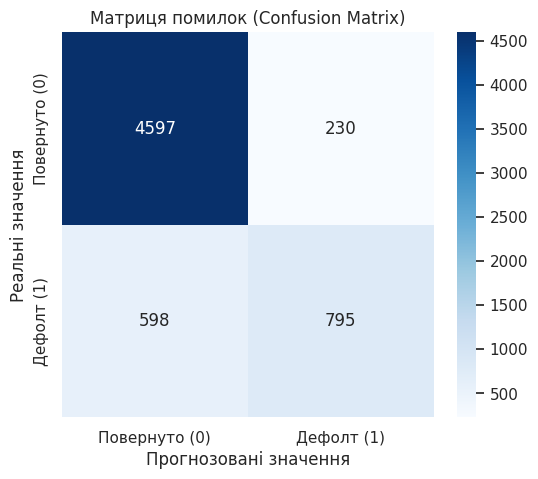

Основні метрики якості (Тестова вибірка)
Accuracy (Загальна точність):   0.8669
Precision (Точність прогнозу):  0.7756
Recall (Повнота виявлення 1):   0.5707
F1-Score (Збалансована метрика): 0.6576


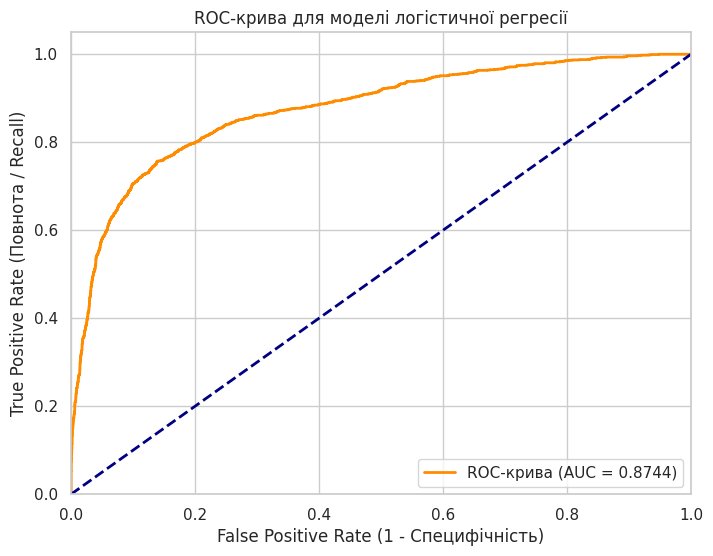

Аналіз важливості ознак
ТОП-5 ознак, які найбільше впливають на прогноз дефолту:
                   Ознака  Коефіцієнт
             loan_grade_G    4.311818
             loan_grade_F    2.742544
             loan_grade_E    2.498114
             loan_grade_D    2.332286
person_home_ownership_OWN   -1.655919


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Повернуто (0)', 'Дефолт (1)'],
            yticklabels=['Повернуто (0)', 'Дефолт (1)'])
plt.title('Матриця помилок (Confusion Matrix)')
plt.xlabel('Прогнозовані значення')
plt.ylabel('Реальні значення')
plt.show()

print("Основні метрики якості (Тестова вибірка)")
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print(f"Accuracy (Загальна точність):   {accuracy:.4f}")
print(f"Precision (Точність прогнозу):  {precision:.4f}")
print(f"Recall (Повнота виявлення 1):   {recall:.4f}")
print(f"F1-Score (Збалансована метрика): {f1:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc_score = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-крива (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('ROC-крива для моделі логістичної регресії')
plt.xlabel('False Positive Rate (1 - Специфічність)')
plt.ylabel('True Positive Rate (Повнота / Recall)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("Аналіз важливості ознак")
importance_df = pd.DataFrame({
    'Ознака': X.columns,
    'Коефіцієнт': log_reg.coef_[0]
})

importance_df['Абсолютне значення'] = importance_df['Коефіцієнт'].abs()
importance_df = importance_df.sort_values(by='Абсолютне значення', ascending=False)

print("ТОП-5 ознак, які найбільше впливають на прогноз дефолту:")
print(importance_df[['Ознака', 'Коефіцієнт']].head(5).to_string(index=False))


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



Метрики при різних порогах
Поріг Precision Recall F1-Score
  0.1    0.3898 0.8851   0.5413
  0.2    0.5304 0.8019   0.6385
  0.3    0.6273 0.7322   0.6757
  0.4    0.7104 0.6569   0.6826
  0.5    0.7756 0.5707   0.6576
  0.6    0.8060 0.4623   0.5876
  0.7    0.8416 0.3546   0.4990
  0.8    0.8816 0.2405   0.3779
  0.9    0.9497 0.1220   0.2163


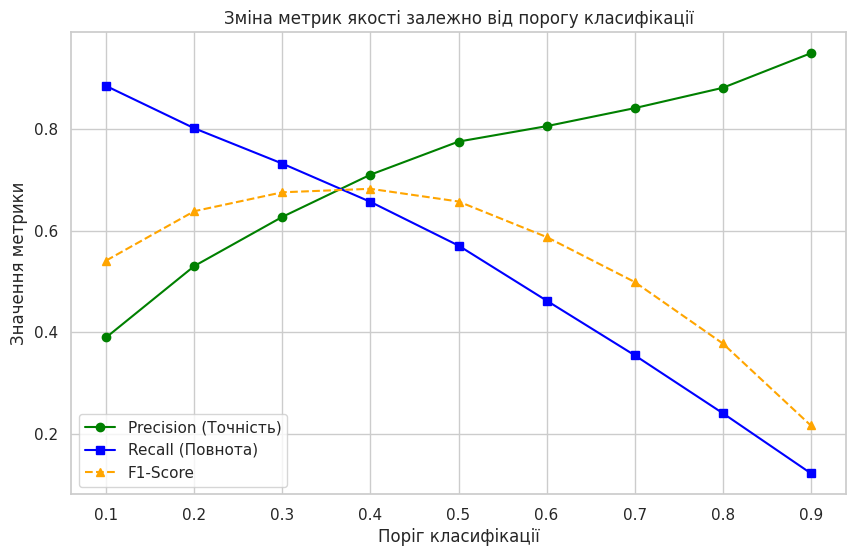

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.1, 1.0, 0.1)

precision_list = []
recall_list = []
f1_list = []

for t in thresholds:
    preds = (y_test_proba >= t).astype(int)

    precision_list.append(precision_score(y_test, preds, zero_division=0))
    recall_list.append(recall_score(y_test, preds))
    f1_list.append(f1_score(y_test, preds))

threshold_results = pd.DataFrame({
    'Поріг': thresholds,
    'Precision': precision_list,
    'Recall': recall_list,
    'F1-Score': f1_list
})

print("Метрики при різних порогах")
print(threshold_results.to_string(index=False, formatters={
    'Поріг': '{:.1f}'.format, 'Precision': '{:.4f}'.format, 'Recall': '{:.4f}'.format, 'F1-Score': '{:.4f}'.format
}))

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_list, label='Precision (Точність)', marker='o', color='green')
plt.plot(thresholds, recall_list, label='Recall (Повнота)', marker='s', color='blue')
plt.plot(thresholds, f1_list, label='F1-Score', marker='^', color='orange', linestyle='--')

plt.title('Зміна метрик якості залежно від порогу класифікації')
plt.xlabel('Поріг класифікації')
plt.ylabel('Значення метрики')
plt.xticks(thresholds)
plt.legend()
plt.grid(True)
plt.show()



---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


In [28]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

tree_model = DecisionTreeClassifier(random_state=42, max_depth=10)
tree_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=15)
rf_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)
y_proba_tree = tree_model.predict_proba(X_test_scaled)[:, 1]

y_pred_rf = rf_model.predict(X_test_scaled)
y_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

metrics_logreg = [
    accuracy_score(y_test, y_test_pred),
    precision_score(y_test, y_test_pred),
    recall_score(y_test, y_test_pred),
    f1_score(y_test, y_test_pred),
    roc_auc_score(y_test, y_test_proba)
]

metrics_tree = [
    accuracy_score(y_test, y_pred_tree),
    precision_score(y_test, y_pred_tree),
    recall_score(y_test, y_pred_tree),
    f1_score(y_test, y_pred_tree),
    roc_auc_score(y_test, y_proba_tree)
]

metrics_rf = [
    accuracy_score(y_test, y_pred_rf),
    precision_score(y_test, y_pred_rf),
    recall_score(y_test, y_pred_rf),
    f1_score(y_test, y_pred_rf),
    roc_auc_score(y_test, y_proba_rf)
]

comparison_df = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Logistic Regression': metrics_logreg,
    'Decision Tree': metrics_tree,
    'Random Forest': metrics_rf
})

print("Порівняння моделей на тестовій вибірці")
print(comparison_df.to_string(index=False, formatters={
    'Logistic Regression': '{:.4f}'.format, 'Decision Tree': '{:.4f}'.format, 'Random Forest': '{:.4f}'.format
}))


Порівняння моделей на тестовій вибірці
  Метрика Logistic Regression Decision Tree Random Forest
 Accuracy              0.8669        0.9190        0.9272
Precision              0.7756        0.9388        0.9554
   Recall              0.5707        0.6827        0.7078
 F1-Score              0.6576        0.7905        0.8132
  ROC-AUC              0.8744        0.8928        0.9271
